# Results: original and estimated dates

In [1]:
import sys
import tempfile

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
ACTIVE_LIFE_PATH = '../../data/enriched_parquets/individual_active_life.parquet'  # 03_b_active_life, not yet in the database

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Dates of `individual_enriched` (ingested by `ingest_dates.py` from notebooks 01 and 05) and the active life of 03_b_active_life:
- **Original**: the date comes from Wikidata (`source = 'wikidata'`), coarse dates included.
- **Estimated**: the date was imputed (`source = 'estimated'`).
- **Original active life**: the earliest and the latest dated work or position held, in different years.
- **Estimated active life**: start and end imputed from the birth year and the cohort, capped at the death.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
dates = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.death_date.year AS death_year,
           individual_enriched.birth_date.source AS birth_source,
           individual_enriched.death_date.source AS death_source,
           individual_enriched.birth_date.coarse_label IS NOT NULL OR individual_enriched.death_date.coarse_label IS NOT NULL AS coarse,
           len(individual.floruit_date) > 0 AS floruit,
           active_life.start_of_active_life.source AS active_source,
           active_life.start_of_active_life.year AS active_start_year,
           active_life.end_of_active_life.year AS active_end_year
    FROM individual_enriched
    JOIN individual ON individual.entity.qid = individual_enriched.entity.qid
    LEFT JOIN read_parquet($active_life) AS active_life ON active_life.qid = individual_enriched.entity.qid
''', params={'active_life': ACTIVE_LIFE_PATH}).pl()
assert dates['qid'].is_unique().all()
print(f'{dates.height:,} individuals')
dates.sample(5, seed=42)

13,002,897 individuals


qid,birth_year,death_year,birth_source,death_source,coarse,floruit,active_source,active_start_year,active_end_year
str,i64,i64,str,str,bool,bool,str,i64,i64
"""Q88428089""",null,null,null,null,false,false,null,null,null
"""Q122303749""",null,null,null,null,false,false,null,null,null
"""Q59094413""",null,null,null,null,false,false,null,null,null
"""Q96956693""",null,null,null,null,false,false,null,null,null
"""Q102394987""",null,null,null,null,false,false,null,null,null


## Counts

In [3]:
period = pl.col('active_start_year') < pl.col('active_end_year')
counts = {
    'Original birth date': pl.col('birth_source') == 'wikidata',
    'Estimated birth date': pl.col('birth_source') == 'estimated',
    'Original death date': pl.col('death_source') == 'wikidata',
    'Estimated death date': pl.col('death_source') == 'estimated',
    'Original active life': (pl.col('active_source') == 'dated works and positions') & period,
    'Estimated active life': pl.col('active_source') == 'estimated',
}
results = pl.DataFrame([
    {'dates': name, 'individuals': dates.filter(rule).height, 'share of the database (%)': 100 * dates.filter(rule).height / dates.height}
    for name, rule in counts.items()
])
single_year = dates.filter((pl.col('active_source') == 'dated works and positions') & ~period).height
print(f'{single_year:,} individuals with dated works and positions all in one year: neither an original nor an estimated active life')

197,104 individuals with dated works and positions all in one year: neither an original nor an estimated active life


### Table: original and estimated dates

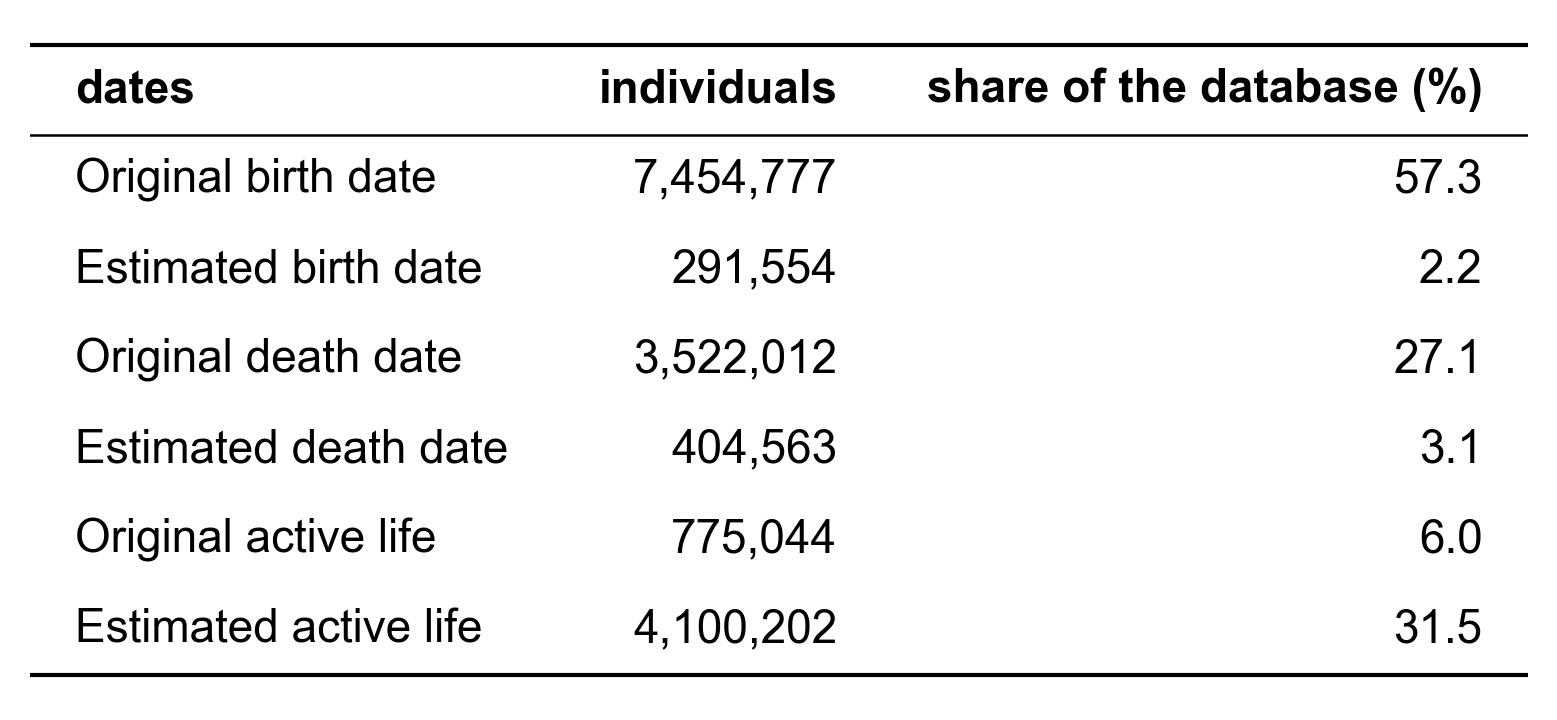

In [4]:
show_table(results, decimals=1)

## Without individuals born after 1920
Individuals with an original or estimated birth year after 1920 are removed; individuals without a birth year are kept. Shares are relative to the remaining individuals.

In [5]:
before_1920 = dates.filter(pl.col('birth_year').is_null() | (pl.col('birth_year') <= 1920))
results_before_1920 = pl.DataFrame([
    {'dates': name, 'individuals': before_1920.filter(rule).height, 'share of the database (%)': 100 * before_1920.filter(rule).height / before_1920.height}
    for name, rule in counts.items()
])
print(f'{dates.height - before_1920.height:,} individuals born after 1920 removed, {before_1920.height:,} remaining')

4,552,759 individuals born after 1920 removed, 8,450,138 remaining


### Table: original and estimated dates, individuals born up to 1920

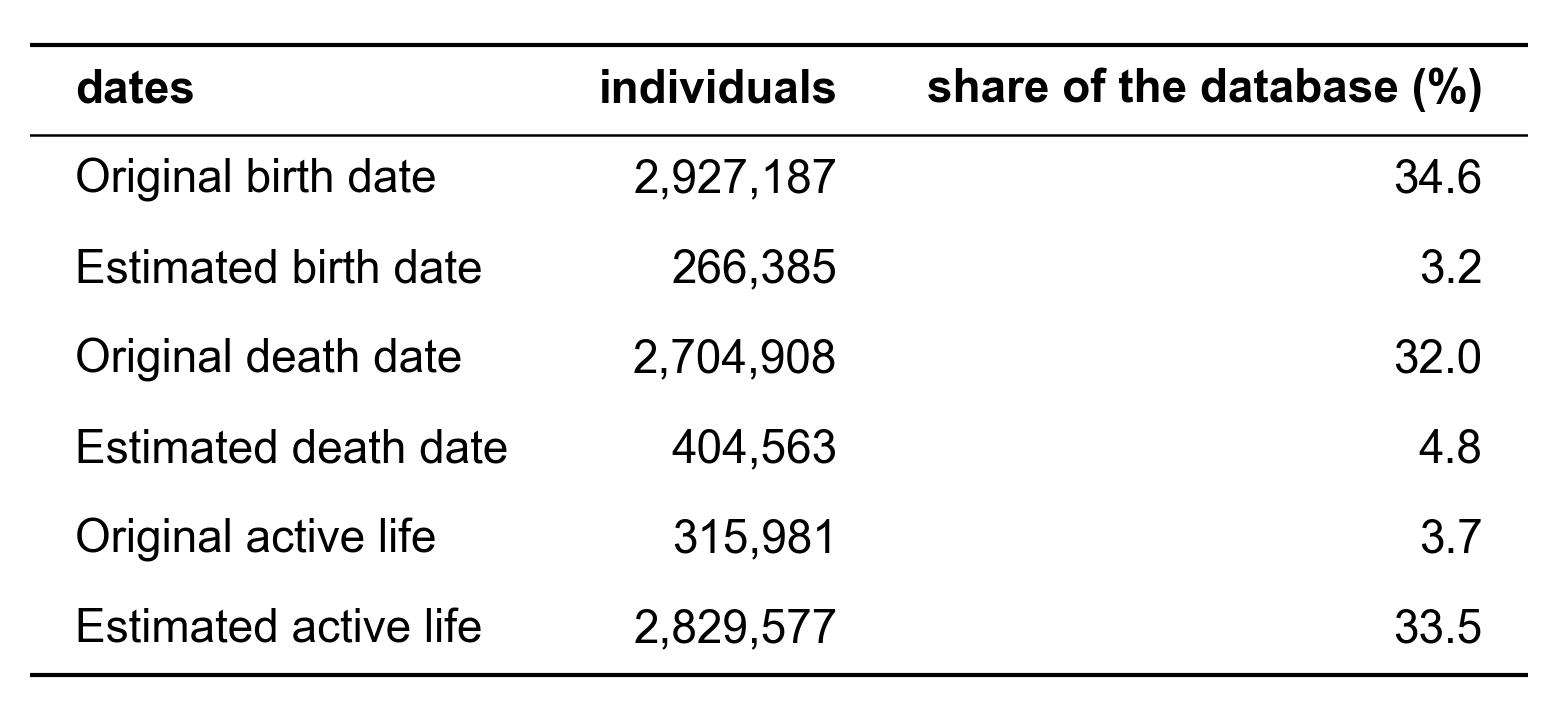

In [6]:
show_table(results_before_1920, decimals=1)

## Summary of what the method added
Cut-offs: a death is estimated only for individuals born up to 1920 (they may still be alive otherwise); an active life is estimated only for individuals born up to 1950 (from Wikidata, else the birth estimated from the age at death), with no dated work or position over several years.

In [7]:
def first_match(rules):
    """The name of the first rule an individual matches."""
    expression = pl.lit(None, pl.String)
    for name, rule in reversed(rules.items()):
        expression = pl.when(rule).then(pl.lit(name)).otherwise(expression)
    return expression


wikidata_birth = (pl.col('birth_source') == 'wikidata') & pl.col('birth_year').is_not_null()
wikidata_death = (pl.col('death_source') == 'wikidata') & pl.col('death_year').is_not_null()
single_year = (pl.col('active_source') == 'dated works and positions') & ~period
GROUPS = {
    'Birth and death': wikidata_birth & wikidata_death,
    'Birth only': wikidata_birth,
    'Death only': wikidata_death,
    'Century or millennium only': pl.col('coarse'),
    'No birth or death date': pl.lit(True),
}
by_group = (
    dates.with_columns(first_match(GROUPS).alias('in Wikidata'))
    .group_by('in Wikidata')
    .agg(
        pl.len().alias('individuals'),
        wikidata_birth.sum().alias('birth'),
        (pl.col('birth_source') == 'estimated').sum().alias('estimated birth'),
        wikidata_death.sum().alias('death'),
        (pl.col('death_source') == 'estimated').sum().alias('estimated death'),
        counts['Original active life'].sum().alias('active life'),
        (pl.col('active_source') == 'estimated').sum().alias('estimated active life'),
    )
    .sort(pl.col('in Wikidata').replace_strict(list(GROUPS), list(range(len(GROUPS)))))
)
total = by_group.select(pl.lit('Total').alias('in Wikidata'), pl.exclude('in Wikidata').sum())
by_group = pl.concat([by_group, total])
by_group

in Wikidata,individuals,birth,estimated birth,death,estimated death,active life,estimated active life
str,u32,u32,u32,u32,u32,u32,u32
"""Birth and death""",3209577,3209577,0,3209577,0,321304,2775457
"""Birth only""",4140220,4140220,0,0,404563,381730,1049557
"""Death only""",291556,0,291554,291556,0,15039,275188
"""Century or millennium only""",108029,0,0,0,0,3051,0
"""No birth or death date""",5253515,0,0,0,0,53920,0
"""Total""",13002897,7349797,291554,3501133,404563,775044,4100202


### Table: dates added, by what Wikidata gave

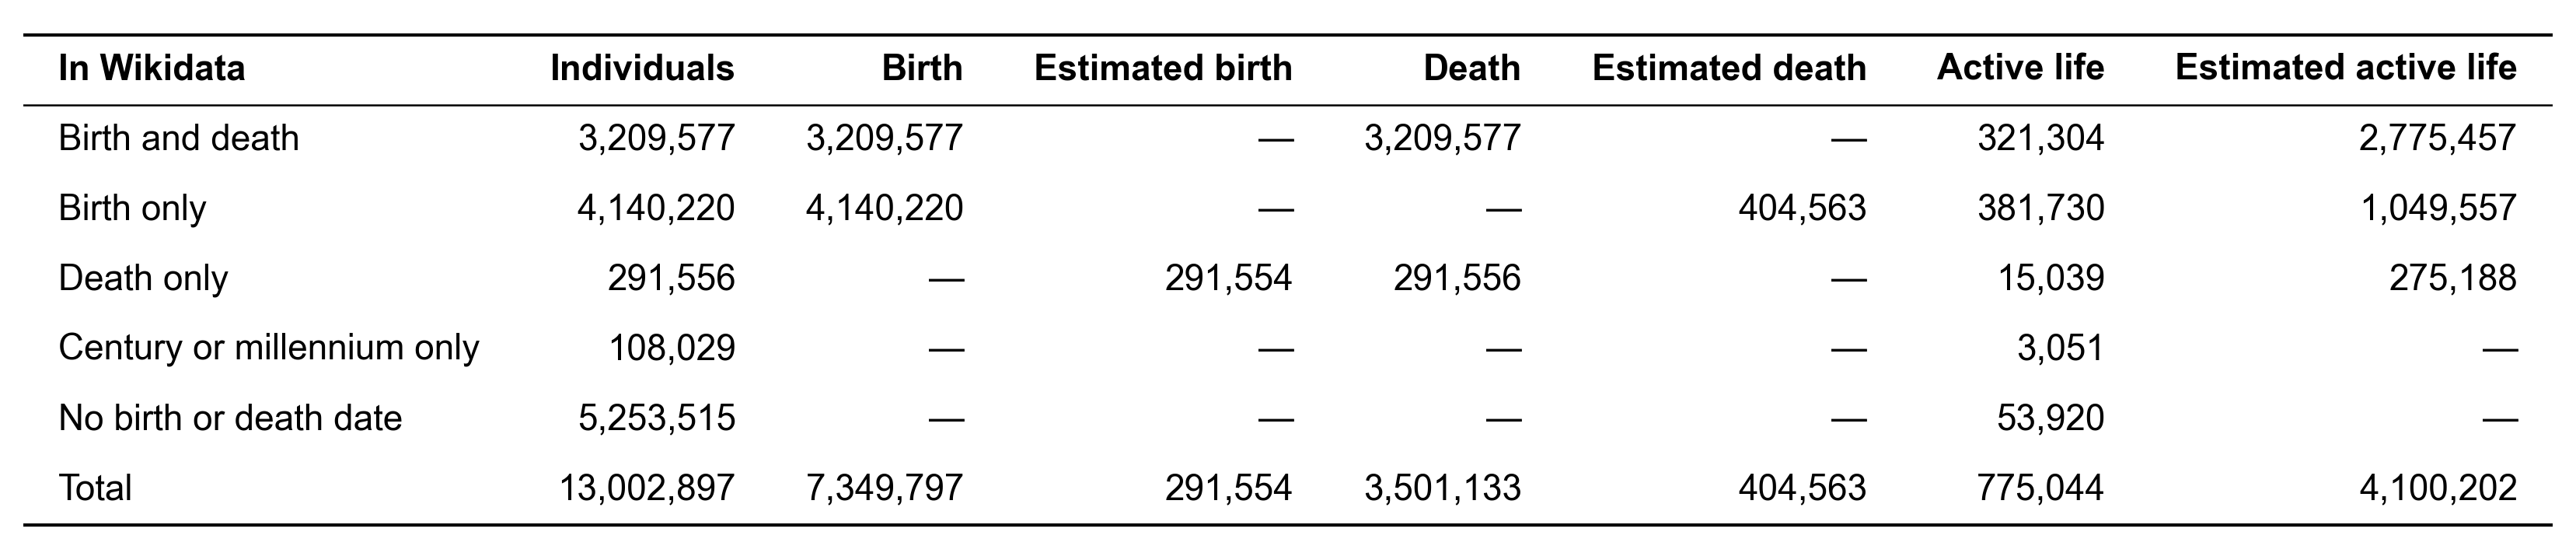

In [8]:
show_table(by_group.with_columns(
    pl.when(pl.col(column) == 0).then(pl.lit('—')).otherwise(pl.col(column).map_elements(lambda v: f'{v:,}', return_dtype=pl.String)).alias(column)
    for column in by_group.columns[1:]
).rename(lambda column: column[0].upper() + column[1:]))  # a dash instead of 0, capitalised column names

In [9]:
no_life_dates = dates.filter(pl.col('birth_year').is_null() & pl.col('death_year').is_null())
REMAINING = {
    'Dated works or positions over several years (original active life)': counts['Original active life'],
    'Century or millennium only': pl.col('coarse'),
    'Floruit and dated works or positions in a single year': pl.col('floruit') & single_year,
    'Dated works or positions in a single year': single_year,
    'Floruit only': pl.col('floruit'),
    'No date': pl.lit(True),
}
remaining = (
    no_life_dates.with_columns(first_match(REMAINING).alias('dates'))
    .group_by('dates').agg(pl.len().alias('individuals'))
    .sort(pl.col('dates').replace_strict(list(REMAINING), list(range(len(REMAINING)))))
)
remaining = pl.concat([remaining, remaining.select(pl.lit('Total').alias('dates'), pl.col('individuals').sum())])
print(f'{no_life_dates.height:,} individuals with neither a birth nor a death year after the method')
remaining

5,361,544 individuals with neither a birth nor a death year after the method


dates,individuals
str,u32
"""Dated works or positions over …",56971
"""Century or millennium only""",104978
"""Floruit and dated works or pos…",1108
"""Dated works or positions in a …",56174
"""Floruit only""",43525
"""No date""",5098788
"""Total""",5361544


### Table: individuals with neither a birth nor a death year after the method

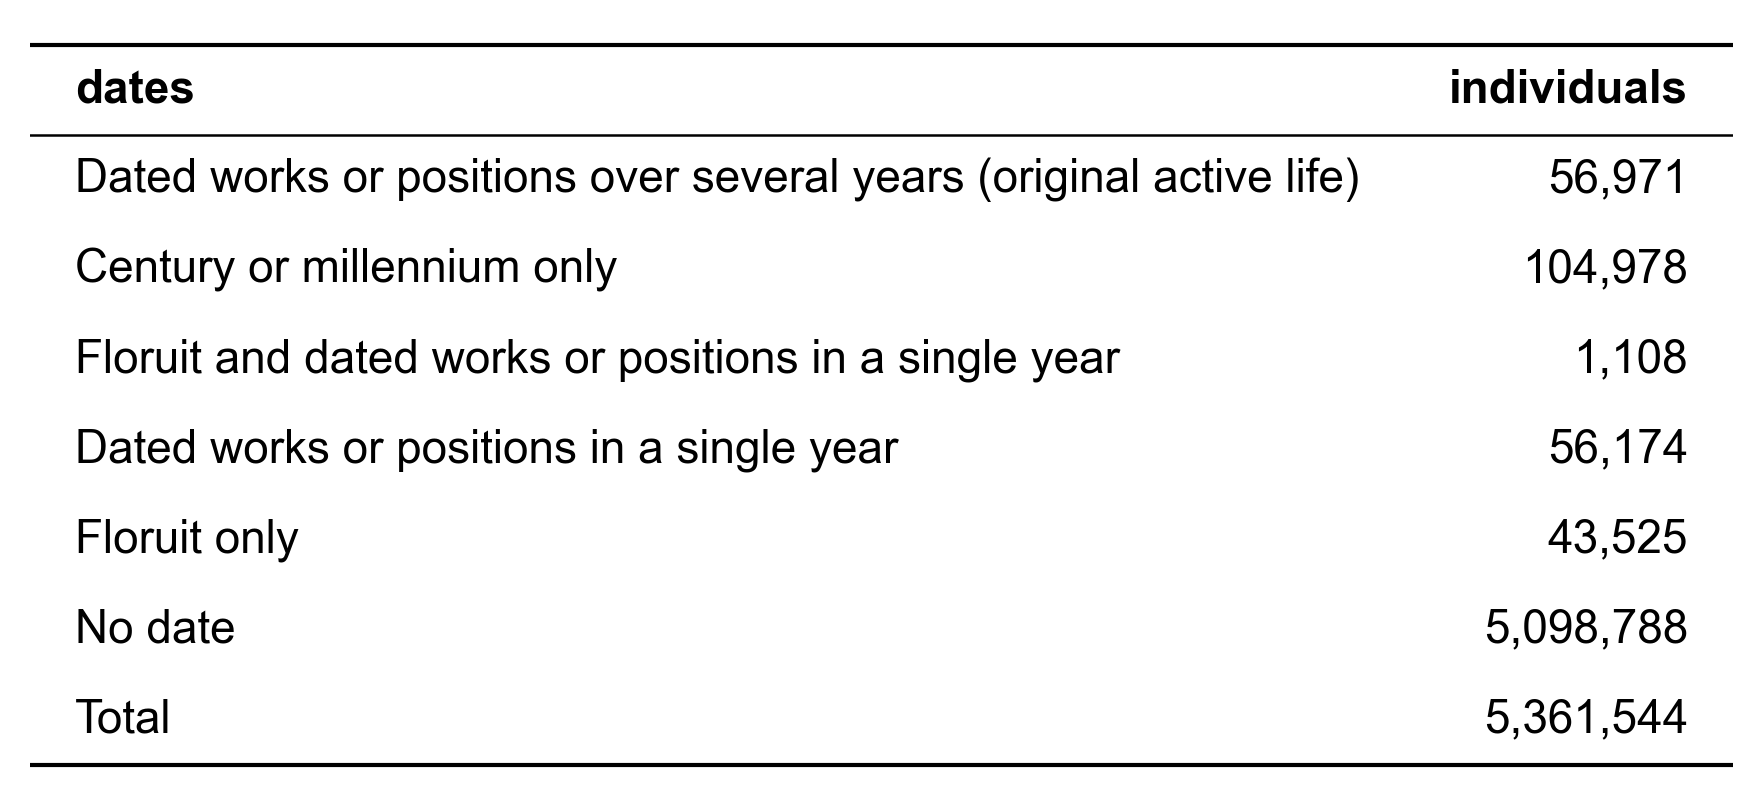

In [10]:
show_table(remaining)